In [ ]:
!pip install git+https://github.com/RudyMorel/scattering_spectra@v2.0.2
!pip install git+https://github.com/RudyMorel/shadowing
!pip install ipywidgets
!pip install shadowing


  Cloning https://github.com/RudyMorel/scattering_spectra (to revision v2.0.2) to /tmp/pip-req-build-kstnel6g
  Running command git clone --filter=blob:none --quiet https://github.com/RudyMorel/scattering_spectra /tmp/pip-req-build-kstnel6g
  Running command git checkout -q fcbbbbe50e36240b0527a347d7e0dc1fb8f4c418
  Resolved https://github.com/RudyMorel/scattering_spectra to commit fcbbbbe50e36240b0527a347d7e0dc1fb8f4c418
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 85.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 63.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 40.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%%writefile generate_dataset.py
import numpy as np
from pathlib import Path
import argparse

def generate_trajectories(n_paths=1000, R=32768, mu=0.0, sigma=0.01):
    """
    Generates simulated trajectories of shape (1, 1, R).
    """
    trajectories = []
    for i in range(n_paths):
        increments = np.random.normal(loc=mu, scale=sigma, size=R)
        traj = increments.reshape(1, 1, R)
        trajectories.append(traj)
    return trajectories

def main():
    parser = argparse.ArgumentParser(description="Generate dataset for shadowing models.")
    parser.add_argument('--n_paths', type=int, default=1000, help='Number of trajectories')
    parser.add_argument('--R', type=int, default=32768, help='Length of each trajectory')
    parser.add_argument('--dataset_path', type=str, default='generated_dataset', help='Output folder')
    parser.add_argument('--mu', type=float, default=0.0, help='Drift')
    parser.add_argument('--sigma', type=float, default=0.01, help='Volatility')
    args = parser.parse_args()

    dataset_dir = Path(args.dataset_path)
    dataset_dir.mkdir(parents=True, exist_ok=True)

    trajectories = generate_trajectories(n_paths=args.n_paths, R=args.R, mu=args.mu, sigma=args.sigma)
    for i, traj in enumerate(trajectories):
        np.save(dataset_dir / f"trajectory_{i}.npy", traj)

    print(f"Generated {args.n_paths} trajectories (each of shape (1,1,{args.R})).")
    print(f"Files are saved in folder: {dataset_dir.resolve()}")

if __name__ == '__main__':
    main()


Writing generate_dataset.py


In [ ]:
!python generate_dataset.py --n_paths 1000 --R 32768 --dataset_path "/content/drive/MyDrive/generated_dataset" --mu 0.0 --sigma 0.01

Generated 1000 trajectories (each of shape (1,1,32768)).
Files are saved in folder: /content/drive/MyDrive/generated_dataset


In [ ]:
import os
dataset_folder = "/content/drive/MyDrive/generated_dataset"
print("Files in dataset folder:")
print(os.listdir(dataset_folder))

import numpy as np
from pathlib import Path
from scatspectra import SPDaily, TimeSeriesDataset

# Load market data (e.g. S&P daily returns)
snp = SPDaily()
# Use the last 20 observations as the past observed log-price path.
x_past = snp.dlnx[0, 0, -20:]  # 𝒙ₚₐₛₜ

# Set the dataset path.
dataset_path = Path("/content/drive/MyDrive/generated_dataset")
# There are 1000 trajectory files; pass R=1000.
dataset = TimeSeriesDataset(dataset_path, R=1000)

print("Market data and dataset loaded successfully!")

Files in dataset folder:
['trajectory_0.npy', 'trajectory_1.npy', 'trajectory_2.npy', 'trajectory_3.npy', 'trajectory_4.npy', 'trajectory_5.npy', 'trajectory_6.npy', 'trajectory_7.npy', 'trajectory_8.npy', 'trajectory_9.npy', 'trajectory_10.npy', 'trajectory_11.npy', 'trajectory_12.npy', 'trajectory_13.npy', 'trajectory_14.npy', 'trajectory_15.npy', 'trajectory_16.npy', 'trajectory_17.npy', 'trajectory_18.npy', 'trajectory_19.npy', 'trajectory_20.npy', 'trajectory_21.npy', 'trajectory_22.npy', 'trajectory_23.npy', 'trajectory_24.npy', 'trajectory_25.npy', 'trajectory_26.npy', 'trajectory_27.npy', 'trajectory_28.npy', 'trajectory_29.npy', 'trajectory_30.npy', 'trajectory_31.npy', 'trajectory_32.npy', 'trajectory_33.npy', 'trajectory_34.npy', 'trajectory_35.npy', 'trajectory_36.npy', 'trajectory_37.npy', 'trajectory_38.npy', 'trajectory_39.npy', 'trajectory_40.npy', 'trajectory_41.npy', 'trajectory_42.npy', 'trajectory_43.npy', 'trajectory_44.npy', 'trajectory_45.npy', 'trajectory_46.npy

<Figure size 6000x4500 with 0 Axes>

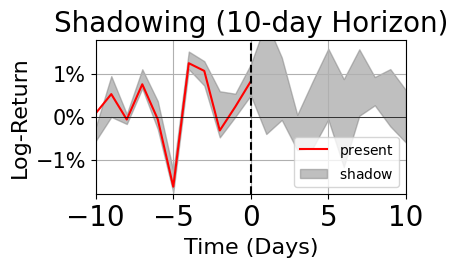

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from shadowing import PathShadowing, Identity, RelativeMSE, PredictionContext, plot_shadow

def compute_shadowing(N_paths=512, horizon=10):
    """
    Sets up and runs the shadowing model.

    Variables:
      - 𝒙ₚₐₛₜ: Past observed log-price path.
      - q(x): Mean square error function (implemented as RelativeMSE).
      - N_paths: Number of shadowing paths to compute.

    Returns distances, close_paths, and the shadowing object.
    """
    context = PredictionContext(horizon=horizon)
    embedding = Identity(x_past.shape[-1])  # Using 𝒙ₚₐₛₜ
    # q(x) is implemented as RelativeMSE.
    distance = RelativeMSE()
    shadow_obj = PathShadowing(embedding=embedding, distance=distance, dataset=dataset, context=context)
    distances, close_paths, _ = shadow_obj.shadow(x_past, k=N_paths, cuda=False)
    return distances, close_paths, shadow_obj

def run_shadowing_plot(N_paths=512, horizon=10, eta=0.11):
    distances, close_paths, _ = compute_shadowing(N_paths, horizon)

    plt.figure(figsize=(40, 30), dpi=150)
    # Plot shadowing paths (here, we simply plot the entire set of paths).
    plot_shadow(x_past, distances[0, :], close_paths[0, :, :, :], eta=eta, color='red')
    # Force x-axis from -10 to 10 days.
    plt.xlim([-10, 10])
    plt.title("Shadowing (10-day Horizon)", fontsize=20)
    plt.xlabel("Time (Days)", fontsize=16)
    plt.ylabel("Log-Return", fontsize=16)
    plt.show()

# For a non-interactive version, simply call the function:
run_shadowing_plot(N_paths=512, horizon=10, eta=0.10)

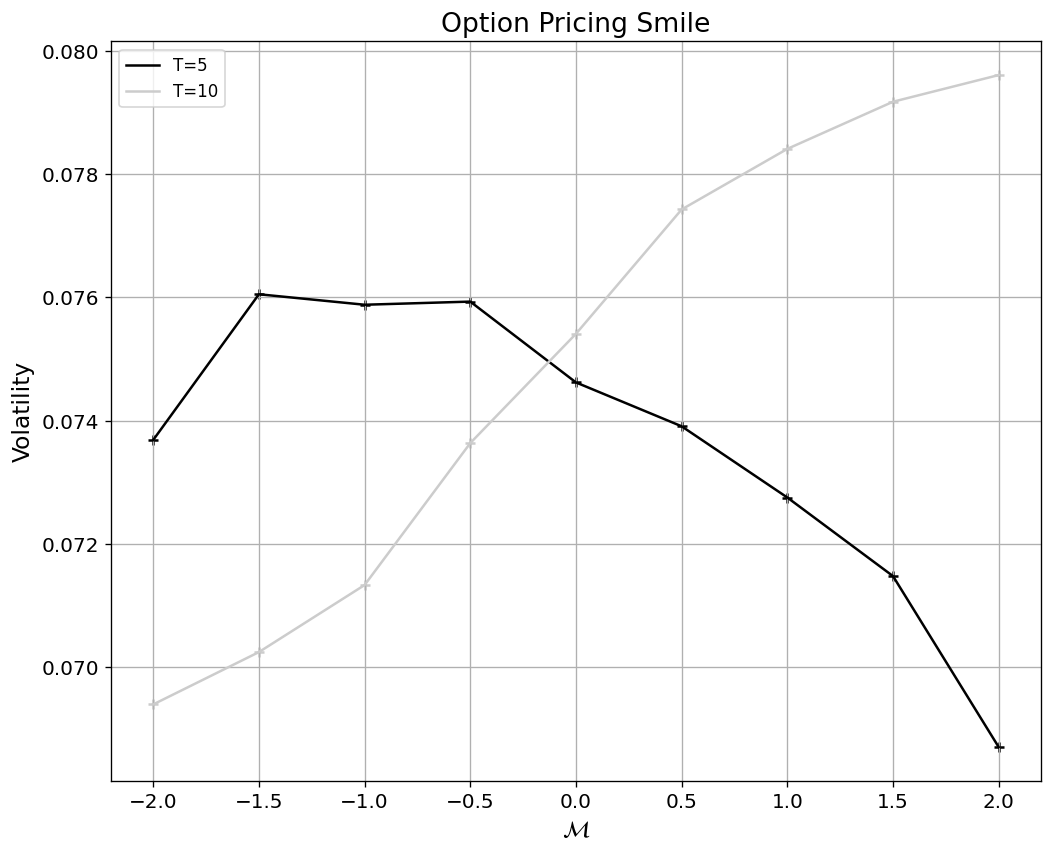

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scatspectra import Softmax, PriceData, compute_smile

def compute_price_paths(N_paths, horizon):
    """
    Computes price paths from shadowing results.

    Returns:
      - x: A NumPy array of shape (N_eff, T_future+1) representing 𝒙ᵏ (the log price paths).
      - distances: The distances from shadowing.
      - N_eff: Effective number of paths.

    We use the last shadowing path (index -1) to extract the future log-returns.
    """
    distances, close_paths, _ = compute_shadowing(N_paths, horizon)
    available = close_paths.shape[1]
    N_eff = min(N_paths, available)
    # Use the last shadowing path (index -1) to get future log-returns.
    dlnx_for_price = close_paths[-1, :N_eff, 0, horizon:]
    x = PriceData(dlnx=dlnx_for_price, x_init=100.0).x  # 𝒙ᵏ, shape: (N_eff, T_future+1)
    return x, distances, N_eff

def run_option_smile(N_paths=512, horizon=10, eta_softmax=0.9, M_points=9, k_strike=100.0):
    """
    Computes and plots the option pricing smile.

    Variables:
      - 𝒙ᵏ: Log price paths of each random variable.
      - 𝔀ₖ: Weight of each price path.
      - k_strike: Option strike price.

    The function pads the time dimension if needed so that compute_smile can operate.
    """
    x, distances, N_eff = compute_price_paths(N_paths, horizon)

    # Ensure the time dimension is at least 21 (so index 20 exists).
    if x.shape[1] < 21:
        pad_width = 21 - x.shape[1]
        x = np.pad(x, ((0,0), (0, pad_width)), mode='edge')

    # Create a Softmax instance and extract weights as 𝔀ₖ.
    w_k = Softmax(distances[-1, :N_eff], eta=eta_softmax)

    # Define moneyness grid and fixed time scales.
    Ms = np.linspace(-2, 2, M_points)
    Ts = np.array([5, 10])  # Two fixed time scales.

    # Compute the option pricing smile.
    # Note: compute_smile internally uses a strike price.
    # Here we assume it uses strike= k_strike (we pass it as 100.0 by default).
    smile_conditional = compute_smile(x, Ts, Ms, ave=w_k)

    # Plot the smile.
    fig, ax = plt.subplots(figsize=(10, 8), dpi=120)
    smile_conditional.plot(ax=ax, color='black', rescale=True, legend=True)
    ax.set_xlabel(r"$\mathcal{M}$", fontsize=14)
    ax.set_ylabel("Volatility", fontsize=14)
    ax.set_title("Option Pricing Smile", fontsize=16)
    ax.tick_params(axis='both', labelsize=12)
    plt.show()

# Run the option smile cell without interactive widgets.
run_option_smile(N_paths=512, horizon=10, eta_softmax=0.11, M_points=9, k_strike=100.0)

Price paths shape (𝒙^k): (1, 500, 21)


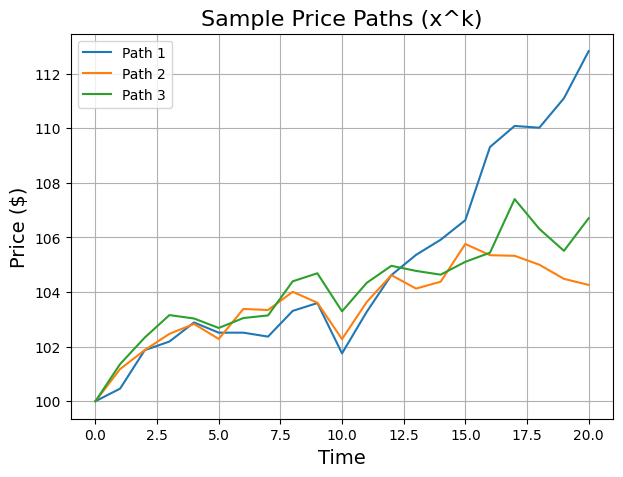

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scatspectra import PriceData
from shadowing import PathShadowing, Identity, RelativeMSE, PredictionContext

# Assume that x_past (past observed log-price path) and dataset are already loaded.
# For example:
# x_past = snp.dlnx[0, 0, -20:]    (this was defined in Cell 6 previously)
# dataset = TimeSeriesDataset(dataset_path, R=1000)

def compute_price_paths(N_paths=500, horizon=5):
    """
    Computes price paths from shadowing results.

    Variables:
      - 𝒙_past: Past observed log-price path.
      - N_paths: Number of random variables (shadowing paths) to compute.
      - q(x): Mean square error function (implemented as RelativeMSE).

    Returns:
      - x_k: A NumPy array of shape (N_eff, T_future+1) representing the price paths 𝒙^k.
      - distances: The distances from the shadowing model.
      - N_eff: The effective number of paths used.
    """
    # Set up the shadowing model using the past observed log-price path (𝒙_past).
    context = PredictionContext(horizon=horizon)
    embedding = Identity(x_past.shape[-1])
    distance = RelativeMSE()  # This is our q(x)
    shadow_obj = PathShadowing(embedding=embedding, distance=distance, dataset=dataset, context=context)

    # Compute shadowing paths (using CPU mode).
    distances, close_paths, _ = shadow_obj.shadow(x_past, k=N_paths, cuda=False)

    available_paths = close_paths.shape[1]
    N_eff = min(N_paths, available_paths)

    # Determine effective horizon based on available future data.
    T_future = close_paths.shape[-1]
    effective_horizon = min(horizon, T_future - 1)  # Ensure at least one future step remains.

    # Use the last shadowing path (index -1) to extract future log-return data.
    # This log-return segment is used to compute the future price paths.
    dlnx_for_price = close_paths[-1, :N_eff, 0, effective_horizon:]

    # Convert the extracted log-returns to price paths (𝒙^k) with an initial price of 100.
    x_k = PriceData(dlnx=dlnx_for_price, x_init=100.0).x  # Expected shape: (N_eff, T_future_effective+1)
    # Expand the dimensions to shape (1, N_eff, T_future_effective+1) for consistency.
    x_k = np.expand_dims(x_k, axis=0)
    return x_k, distances, N_eff

def run_compute_price_paths():
    # Use default parameters: N_paths = 500, horizon = 5.
    N_paths = 500
    horizon = 5
    x_k, distances, N_eff = compute_price_paths(N_paths, horizon)
    print("Price paths shape (𝒙^k):", x_k.shape)

    # Plot a few sample price paths (𝒙^k) for visualization.
    plt.figure(figsize=(7, 5))
    num_paths = min(3, N_eff)
    for i in range(num_paths):
        plt.plot(x_k[0, i, :], label=f'Path {i+1}')
    plt.title("Sample Price Paths (x^k)", fontsize=16)
    plt.xlabel("Time", fontsize=14)
    plt.ylabel("Price ($)", fontsize=14)
    plt.legend()
    plt.grid(True)
    plt.show()

# Run the cell to compute and display sample price paths.
run_compute_price_paths()


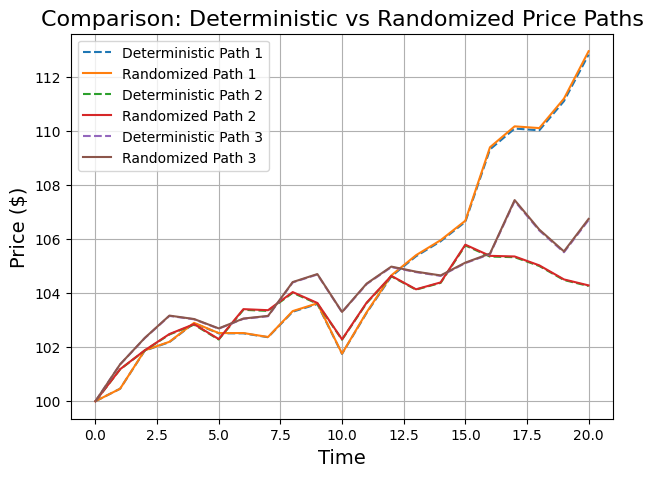

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scatspectra import PriceData
from shadowing import PathShadowing, Identity, RelativeMSE, PredictionContext

# Assume that x_past (past observed log-price path) and dataset are already loaded.

def compute_price_paths(N_paths=500, horizon=5, randomized=False):
    context = PredictionContext(horizon=horizon)
    embedding = Identity(x_past.shape[-1])
    distance = RelativeMSE()
    shadow_obj = PathShadowing(embedding=embedding, distance=distance, dataset=dataset, context=context)

    distances, close_paths, _ = shadow_obj.shadow(x_past, k=N_paths, cuda=False)
    available_paths = close_paths.shape[1]
    N_eff = min(N_paths, available_paths)
    T_future = close_paths.shape[-1]
    effective_horizon = min(horizon, T_future - 1)

    dlnx_for_price = close_paths[-1, :N_eff, 0, effective_horizon:]

    if randomized:
        market_sentiment = np.random.uniform(-1, 1)
        random_volatility = np.abs(np.random.normal(loc=0.01 + 0.005 * market_sentiment, scale=0.005, size=dlnx_for_price.shape))
        dlnx_for_price *= (1 + random_volatility)

    x_k = PriceData(dlnx=dlnx_for_price, x_init=100.0).x
    x_k = np.expand_dims(x_k, axis=0)
    return x_k, distances, N_eff

def run_compute_price_paths():
    N_paths = 500
    horizon = 5
    x_k_det, _, N_eff_det = compute_price_paths(N_paths, horizon, randomized=False)
    x_k_rand, _, N_eff_rand = compute_price_paths(N_paths, horizon, randomized=True)

    plt.figure(figsize=(7, 5))
    num_paths = min(3, N_eff_det, N_eff_rand)

    for i in range(num_paths):
        plt.plot(x_k_det[0, i, :], label=f'Deterministic Path {i+1}', linestyle='dashed')
        plt.plot(x_k_rand[0, i, :], label=f'Randomized Path {i+1}')

    plt.title("Comparison: Deterministic vs Randomized Price Paths", fontsize=16)
    plt.xlabel("Time", fontsize=14)
    plt.ylabel("Price ($)", fontsize=14)
    plt.legend()
    plt.grid(True)
    plt.show()

run_compute_price_paths()


[*********************100%***********************]  1 of 1 completed


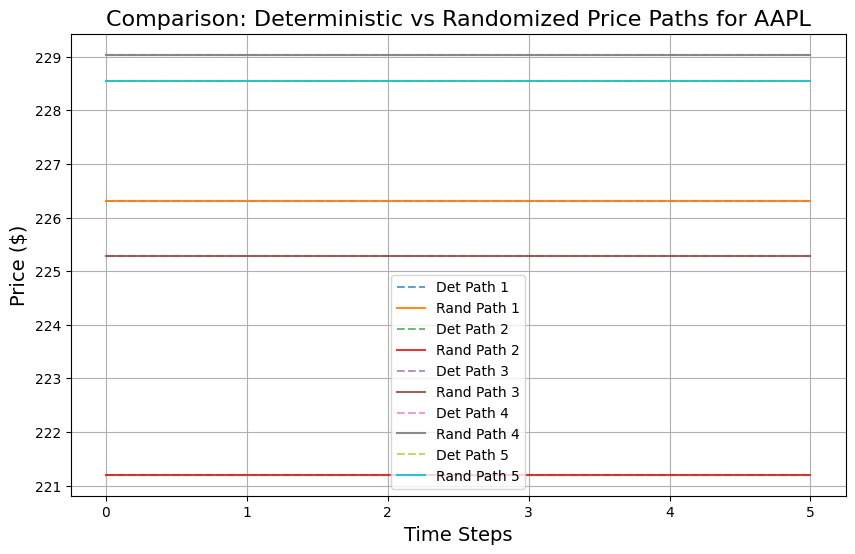

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

# Fetch historical data for Apple (AAPL)
stock_data = yf.download('AAPL', period='6mo', interval='1d')
closing_prices = stock_data['Close'].values

# Compute log returns
log_returns = np.diff(np.log(closing_prices))

def compute_price_paths(N_paths=500, horizon=5, randomized=False):
    N_eff = min(N_paths, len(log_returns) - horizon)
    x_k = np.zeros((1, N_eff, horizon + 1))

    for i in range(N_eff):
        dlnx_for_price = log_returns[i:i+horizon].copy()

        if randomized:
            market_sentiment = np.random.uniform(-1, 1)  # Random sentiment factor
            random_volatility = np.random.normal(loc=0.02 * market_sentiment, scale=0.01, size=dlnx_for_price.shape)
            dlnx_for_price += random_volatility  # Apply randomized perturbation

        x_k[0, i, :] = closing_prices[i] * np.exp(np.cumsum(np.insert(dlnx_for_price, 0, 0)))

    return x_k, N_eff

def run_compute_price_paths():
    N_paths = 500
    horizon = 5
    x_k_det, N_eff_det = compute_price_paths(N_paths, horizon, randomized=False)
    x_k_rand, N_eff_rand = compute_price_paths(N_paths, horizon, randomized=True)

    plt.figure(figsize=(10, 6))
    num_paths = min(5, N_eff_det, N_eff_rand)

    for i in range(num_paths):
        plt.plot(x_k_det[0, i, :], label=f'Det Path {i+1}', linestyle='dashed', alpha=0.7)
        plt.plot(x_k_rand[0, i, :], label=f'Rand Path {i+1}', alpha=0.9)

    plt.title("Comparison: Deterministic vs Randomized Price Paths for AAPL", fontsize=16)
    plt.xlabel("Time Steps", fontsize=14)
    plt.ylabel("Price ($)", fontsize=14)
    plt.legend()
    plt.grid(True)
    plt.show()

run_compute_price_paths()

<Figure size 1200x600 with 0 Axes>

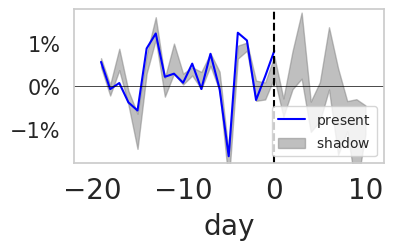

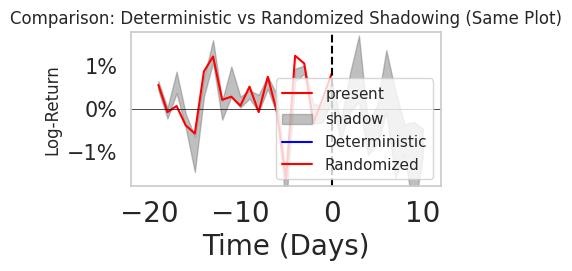

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from shadowing import PathShadowing, Identity, RelativeMSE, PredictionContext, plot_shadow
from scatspectra import SPDaily, TimeSeriesDataset
from pathlib import Path

# Load market data (e.g., S&P daily returns)
snp = SPDaily()
x_past = snp.dlnx[0, 0, -20:]

# Load dataset
dataset_path = Path("/content/drive/MyDrive/generated_dataset")
dataset = TimeSeriesDataset(dataset_path, R=1000)

# Function to compute shadowing with random volatility
def compute_randomized_shadowing(N_paths=512, horizon=10):
    np.random.seed(42)  # For reproducibility
    random_sigma = np.abs(np.random.normal(loc=0.01, scale=0.005, size=N_paths))

    context = PredictionContext(horizon=horizon)
    embedding = Identity(x_past.shape[-1])
    distance = RelativeMSE()

    shadow_obj = PathShadowing(embedding=embedding, distance=distance, dataset=dataset, context=context)
    distances, close_paths, _ = shadow_obj.shadow(x_past, k=N_paths, cuda=False)
    return distances, close_paths, shadow_obj, random_sigma

# Function to plot deterministic vs. randomized approach in the same plot
def compare_shadowing(N_paths=512, horizon=10, eta=0.10):
    distances_det, close_paths_det, _ = compute_shadowing(N_paths, horizon)
    distances_rand, close_paths_rand, _, random_sigma = compute_randomized_shadowing(N_paths, horizon)

    plt.figure(figsize=(12, 6))

    # Plot deterministic shadowing in blue
    plot_shadow(x_past, distances_det[0, :], close_paths_det[0, :, :, :], eta=eta, color='blue')

    # Plot randomized shadowing in red (on the same plot)
    plot_shadow(x_past, distances_rand[0, :], close_paths_rand[0, :, :, :], eta=eta, color='red')

    # Add legend manually
    plt.plot([], [], color='blue', label='Deterministic')
    plt.plot([], [], color='red', label='Randomized')

    plt.title("Comparison: Deterministic vs Randomized Shadowing (Same Plot)")
    plt.xlabel("Time (Days)")
    plt.ylabel("Log-Return")
    plt.legend()
    plt.show()

# Run the comparison
compare_shadowing(N_paths=512, horizon=10, eta=0.10)